In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Фіксація seed за номером варіанта (1) для Києва
np.random.seed(1)
city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
print("Набір даних успішно підготовлено:")
display(climate.head())

Набір даних успішно підготовлено:


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Київ,Січ,-4,24,3.0
1,Київ,Лют,-3,20,1.9
2,Київ,Бер,2,17,0.2
3,Київ,Кві,9,12,1.0
4,Київ,Тра,15,3,0.2


In [99]:
# Завдання 1. Побудова моделі регресії
X = climate["температура"]
Y = climate["витрати_на_опалення"]

reg_result = linregress(X, Y)

print(f"Нахил (slope / b1) = {reg_result.slope:.3f}")
print(f"Перетин (intercept / b0) = {reg_result.intercept:.3f}")
print(f"R² = {reg_result.rvalue**2:.3f}")
print(f"p-value = {reg_result.pvalue:.4e}")

Нахил (slope / b1) = -0.124
Перетин (intercept / b0) = 2.317
R² = 0.650
p-value = 1.5285e-03


In [100]:
# 1. Через квадрат rvalue
r2_method1 = reg_result.rvalue ** 2

# 2. Через суми квадратів (SS_res / SS_tot)
predicted_y = reg_result.intercept + reg_result.slope * X
residuals = Y - predicted_y

ss_residual = np.sum(residuals ** 2)
ss_total = np.sum((Y - Y.mean()) ** 2)
r2_method2 = 1 - (ss_residual / ss_total)

print(f"R² через rvalue**2: {r2_method1:.4f}")
print(f"R² через формулу SS: {r2_method2:.4f}")
print(f"Збігаються результати? {np.isclose(r2_method1, r2_method2)}")

R² через rvalue**2: 0.6504
R² через формулу SS: 0.6504
Збігаються результати? True


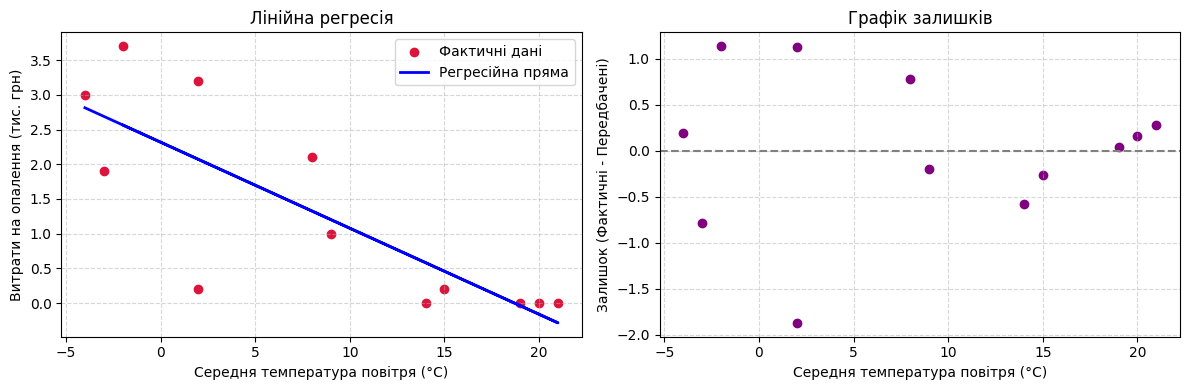

In [101]:
# Завдання 3. Побудова графіка регресії та залишків
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Графік регресійної прямої
ax1.scatter(X, Y, color="crimson", label="Фактичні дані")
ax1.plot(X, predicted_y, color="blue", linewidth=2, label="Регресійна пряма")
ax1.set_xlabel("Середня температура повітря (°C)")
ax1.set_ylabel("Витрати на опалення (тис. грн)")
ax1.set_title("Лінійна регресія")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Графік залишків
ax2.scatter(X, residuals, color="purple")
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xlabel("Середня температура повітря (°C)")
ax2.set_ylabel("Залишок (Фактичні - Передбачені)")
ax2.set_title("Графік залишків")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [102]:
# Завдання 4. Прогноз для температури -10°C
temp_new = -10.0
predicted_cost = reg_result.intercept + reg_result.slope * temp_new

print(f"Прогнозовані витрати для -10°C: {predicted_cost:.2f} тис. грн")
print(f"Спостережений діапазон температур у вибірці: від {X.min()}°C до {X.max()}°C")

Прогнозовані витрати для -10°C: 3.56 тис. грн
Спостережений діапазон температур у вибірці: від -4°C до 21°C


### Відповіді на контрольні запитання:

1. **Чому метод найменших квадратів мінімізує суму квадратів залишків, а не модулів:**
   - Мінімізація суми квадратів залишків (МНК) має зручні математичні та диференційовні властивості, що дозволяє легко отримати аналітичні формули для нахилу та перетину регресії. Крім того, зведення у квадрат сильніше штрафує великі помилки (викиди), роблячи модель стійкішою до грубих відхилень.

2. **Змістовний сенс нахилу $b_1$ і його відмінність від кореляції $r$:**
   - Нахил $b_1$ вимірює абсолютну швидкість зміни залежної змінної $Y$ при зміні $X$ на одну одиницю (в реальних фізичних чи грошових одиницях вимірювання). Натомість коефіцієнт кореляції $r$ є безрозмірним стандартизованим показником сили зв'язку від -1 до 1.

3. **Чому високий $R^2$ не гарантує адекватності лінійної моделі:**
   - Високий $R^2$ свідчить лише про тісний зв'язок, але модель може бути нелінійною. Графік залишків дозволяє виявити приховані систематичні патерни (наприклад, дугоподібну форму чи гетероскедастичність), які вказують на те, що пряма лінія погано описує реальний процес.

4. **Що змінюється в надійності прогнозу при виході за межі вибірки (екстраполяція):**
   - Надійність різко паждає, оскільки модель жодним чином не перевірена за межами спостереженого діапазону. Припущення про збереження тенденції в незвіданій зоні часто призводить до грубих помилок.